# Stratified Analyses

Pathogen class and infection source — v4 primary pool

In [ ]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(brms)
  library(posterior)
  library(ggdist)
  library(gt)
  library(patchwork)
})


Pool: 100 studies (inclusive_pool=FALSE, drop_contaminated=TRUE)

In [ ]:
source("R/02_fit_models.R")
base_post <- pooled_summary(fits$fit_base)


# Pathogen class

## Available data

In [ ]:
es_mort |>
  mutate(pathogen_class = coalesce(pathogen_class, "not reported")) |>
  count(pathogen_class, name = "Effect sizes") |>
  mutate(
    `Pooled?` = if_else(`Effect sizes` >= 3, "Yes", "No — too sparse"),
    pathogen_class = recode(pathogen_class,
      gram_positive  = "Gram-positive",
      gram_negative  = "Gram-negative",
      fungal         = "Fungal",
      mixed          = "Mixed",
      `not reported` = "Not reported"
    )
  ) |>
  arrange(desc(`Effect sizes`)) |>
  rename(`Pathogen class` = pathogen_class) |>
  gt() |>
  tab_style(style = cell_fill(color = "#FEF3CD"),
            locations = cells_body(rows = `Pooled?` == "No — too sparse"))


## Pooled estimates per class

In [ ]:

post_gpos <- if (!is.null(fits$fit_gram_pos)) pooled_summary(fits$fit_gram_pos) else NULL
post_gneg <- if (!is.null(fits$fit_gram_neg)) pooled_summary(fits$fit_gram_neg) else NULL
post_fung <- if (!is.null(fits$fit_fungal))   pooled_summary(fits$fit_fungal)   else NULL

make_row <- function(label, n, post) {
  if (is.null(post))
    return(tibble(Class = label, N = n, `Median OR` = "—",
                  `95% CrI` = "—", `P(harm)` = "—", `I²` = "—"))
  tibble(
    Class      = label,
    N          = n,
    `Median OR` = sprintf("%.2f", post$median_OR),
    `95% CrI`  = sprintf("[%.2f, %.2f]", post$ci_OR[1], post$ci_OR[2]),
    `P(harm)`  = sprintf("%.0f%%", post$p_harm * 100),
    `I²`       = sprintf("%.0f%%", post$median_i2)
  )
}

bind_rows(
  make_row("Gram-negative", sum(es_mort$pathogen_class == "gram_negative", na.rm = TRUE), post_gneg),
  make_row("Gram-positive", sum(es_mort$pathogen_class == "gram_positive", na.rm = TRUE), post_gpos),
  make_row("Fungal",        sum(es_mort$pathogen_class == "fungal",        na.rm = TRUE), post_fung)
) |>
  gt() |>
  tab_style(style = cell_text(style = "italic", color = "gray40"),
            locations = cells_body(rows = Class == "Fungal")) |>
  tab_footnote("Fungal pool contains only 6 effect sizes; estimates are highly uncertain.",
               locations = cells_body(columns = Class, rows = Class == "Fungal"))


## Posterior densities

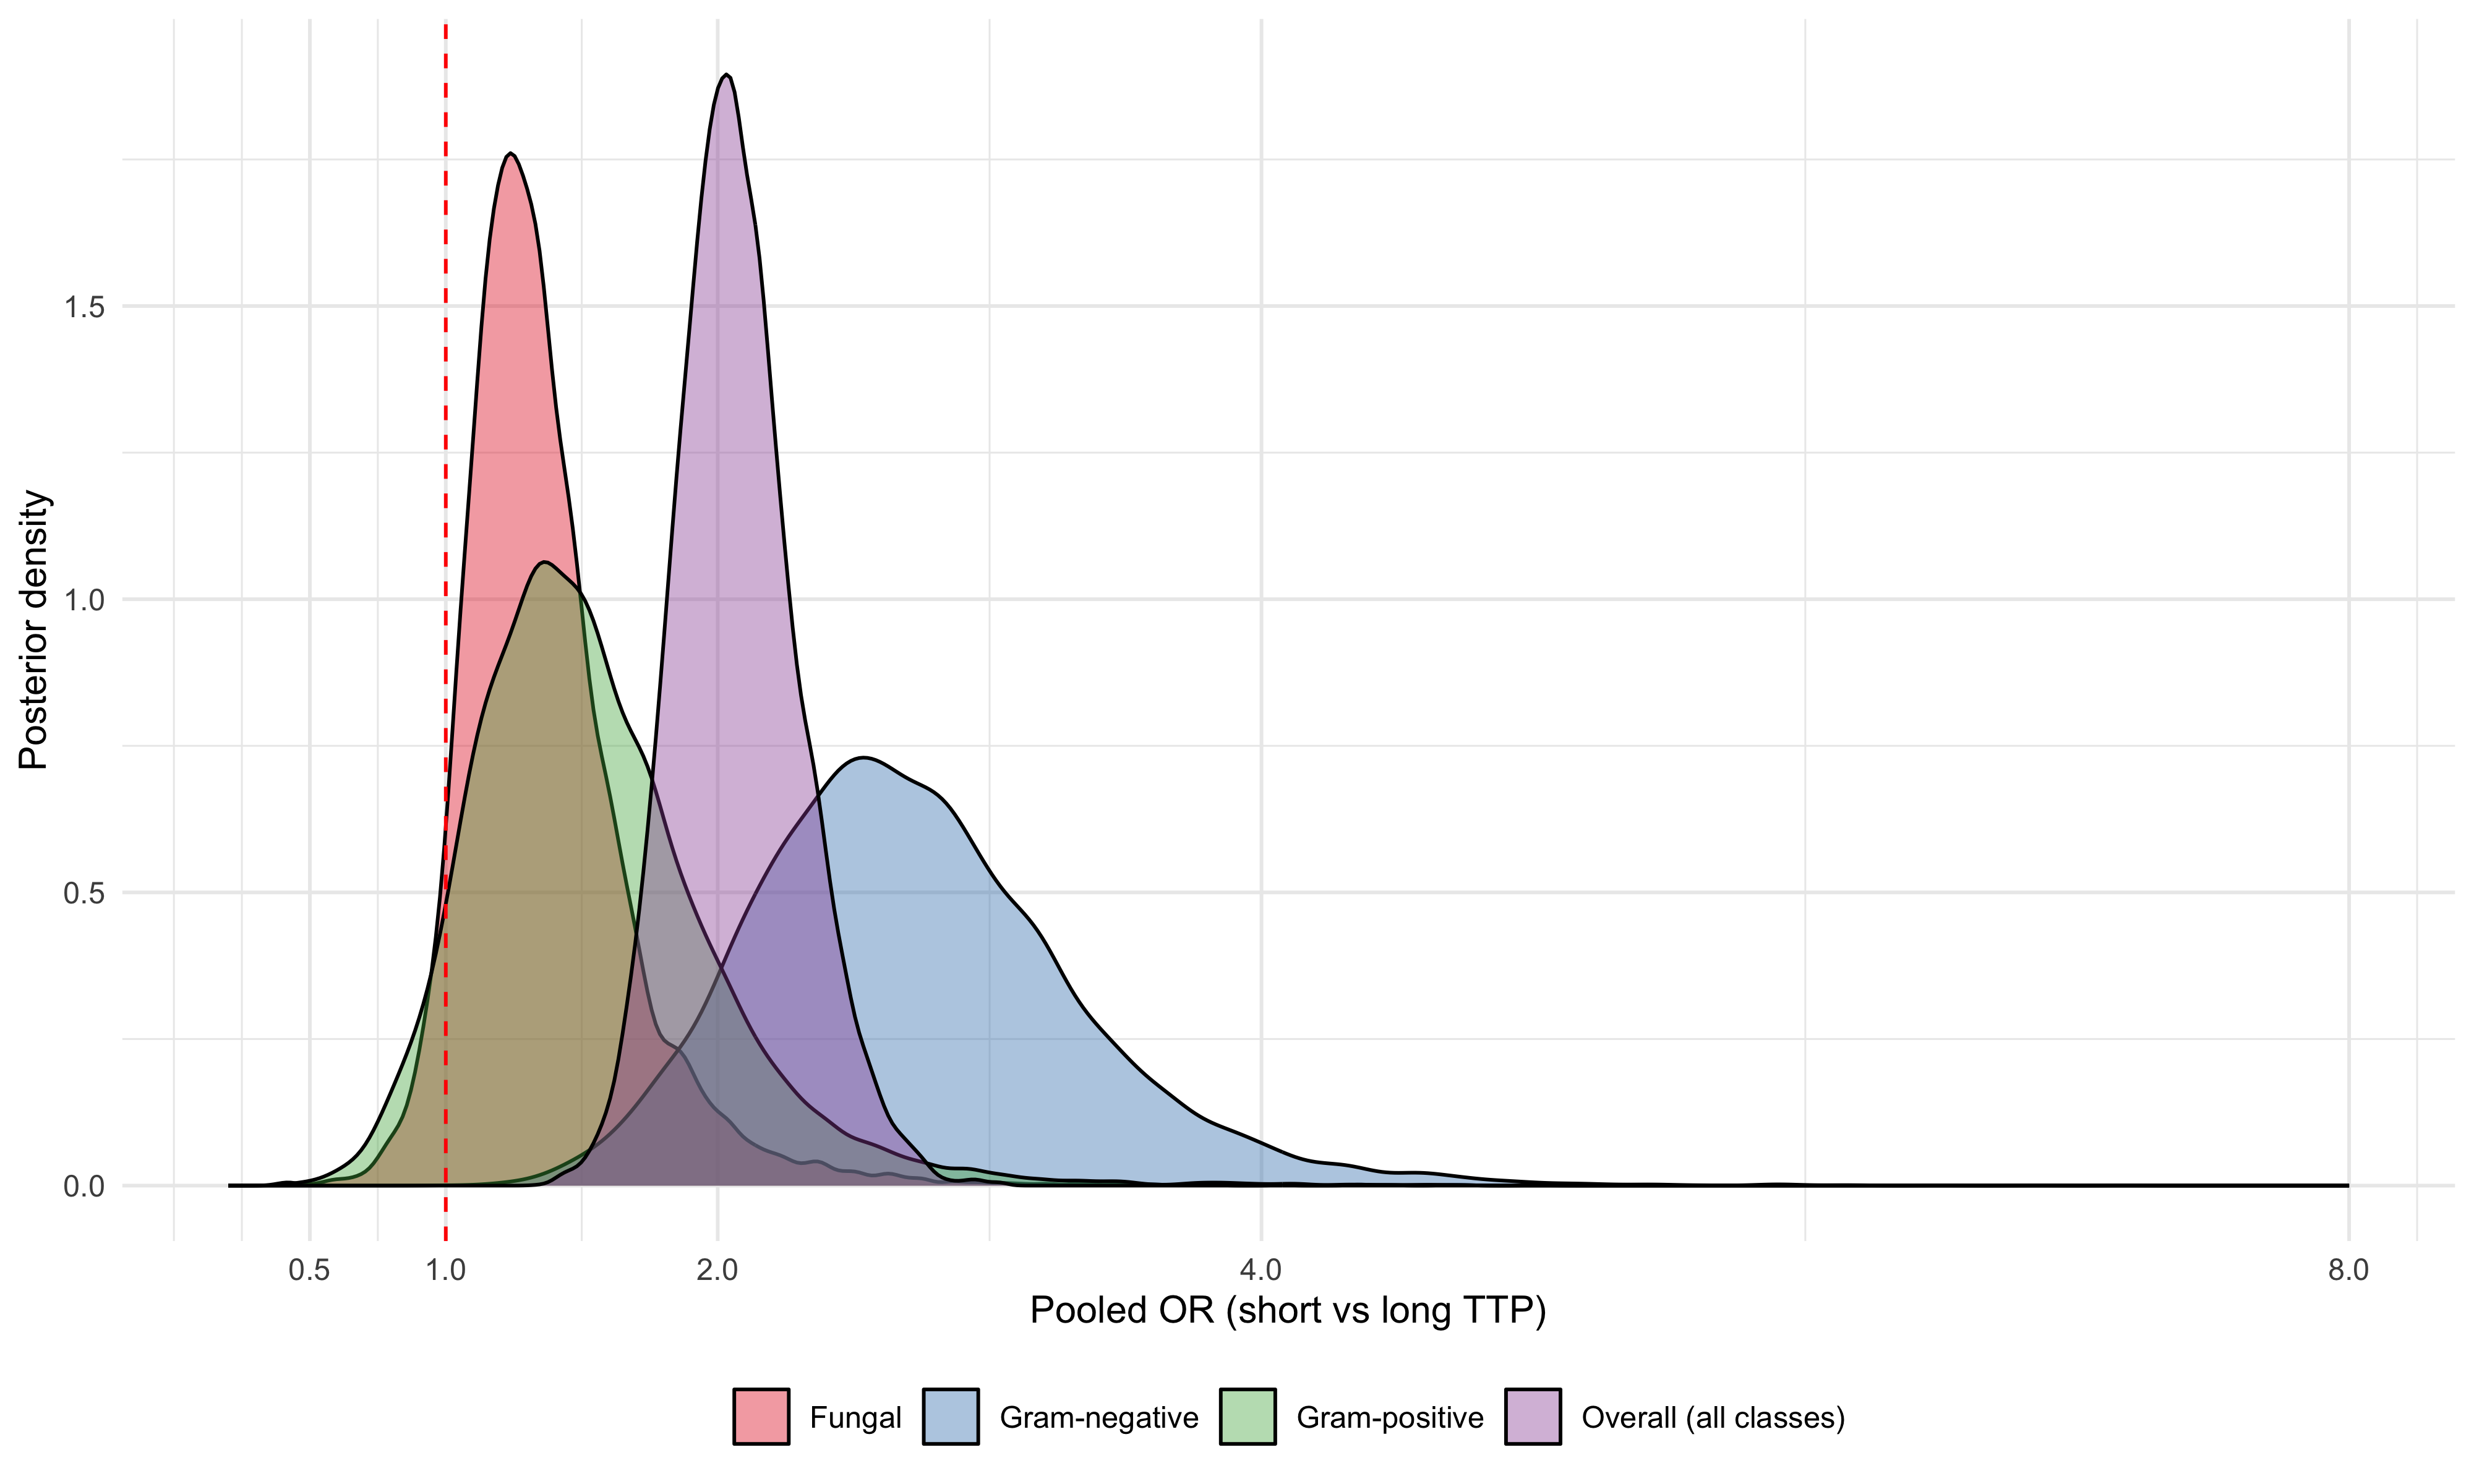

In [ ]:

density_data <- bind_rows(
  tibble(OR = base_post$OR_draws, Class = "Overall (all classes)"),
  if (!is.null(post_gneg)) tibble(OR = post_gneg$OR_draws, Class = "Gram-negative"),
  if (!is.null(post_gpos)) tibble(OR = post_gpos$OR_draws, Class = "Gram-positive"),
  if (!is.null(post_fung)) tibble(OR = post_fung$OR_draws, Class = "Fungal")
)

ggplot(density_data, aes(x = OR, fill = Class)) +
  geom_density(alpha = 0.40) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "red") +
  scale_x_continuous(limits = c(0.2, 8), breaks = c(0.5, 1, 2, 4, 8)) +
  scale_fill_brewer(palette = "Set1") +
  labs(x = "Pooled OR (short vs long TTP)", y = "Posterior density", fill = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom")


## Forest plot by pathogen class

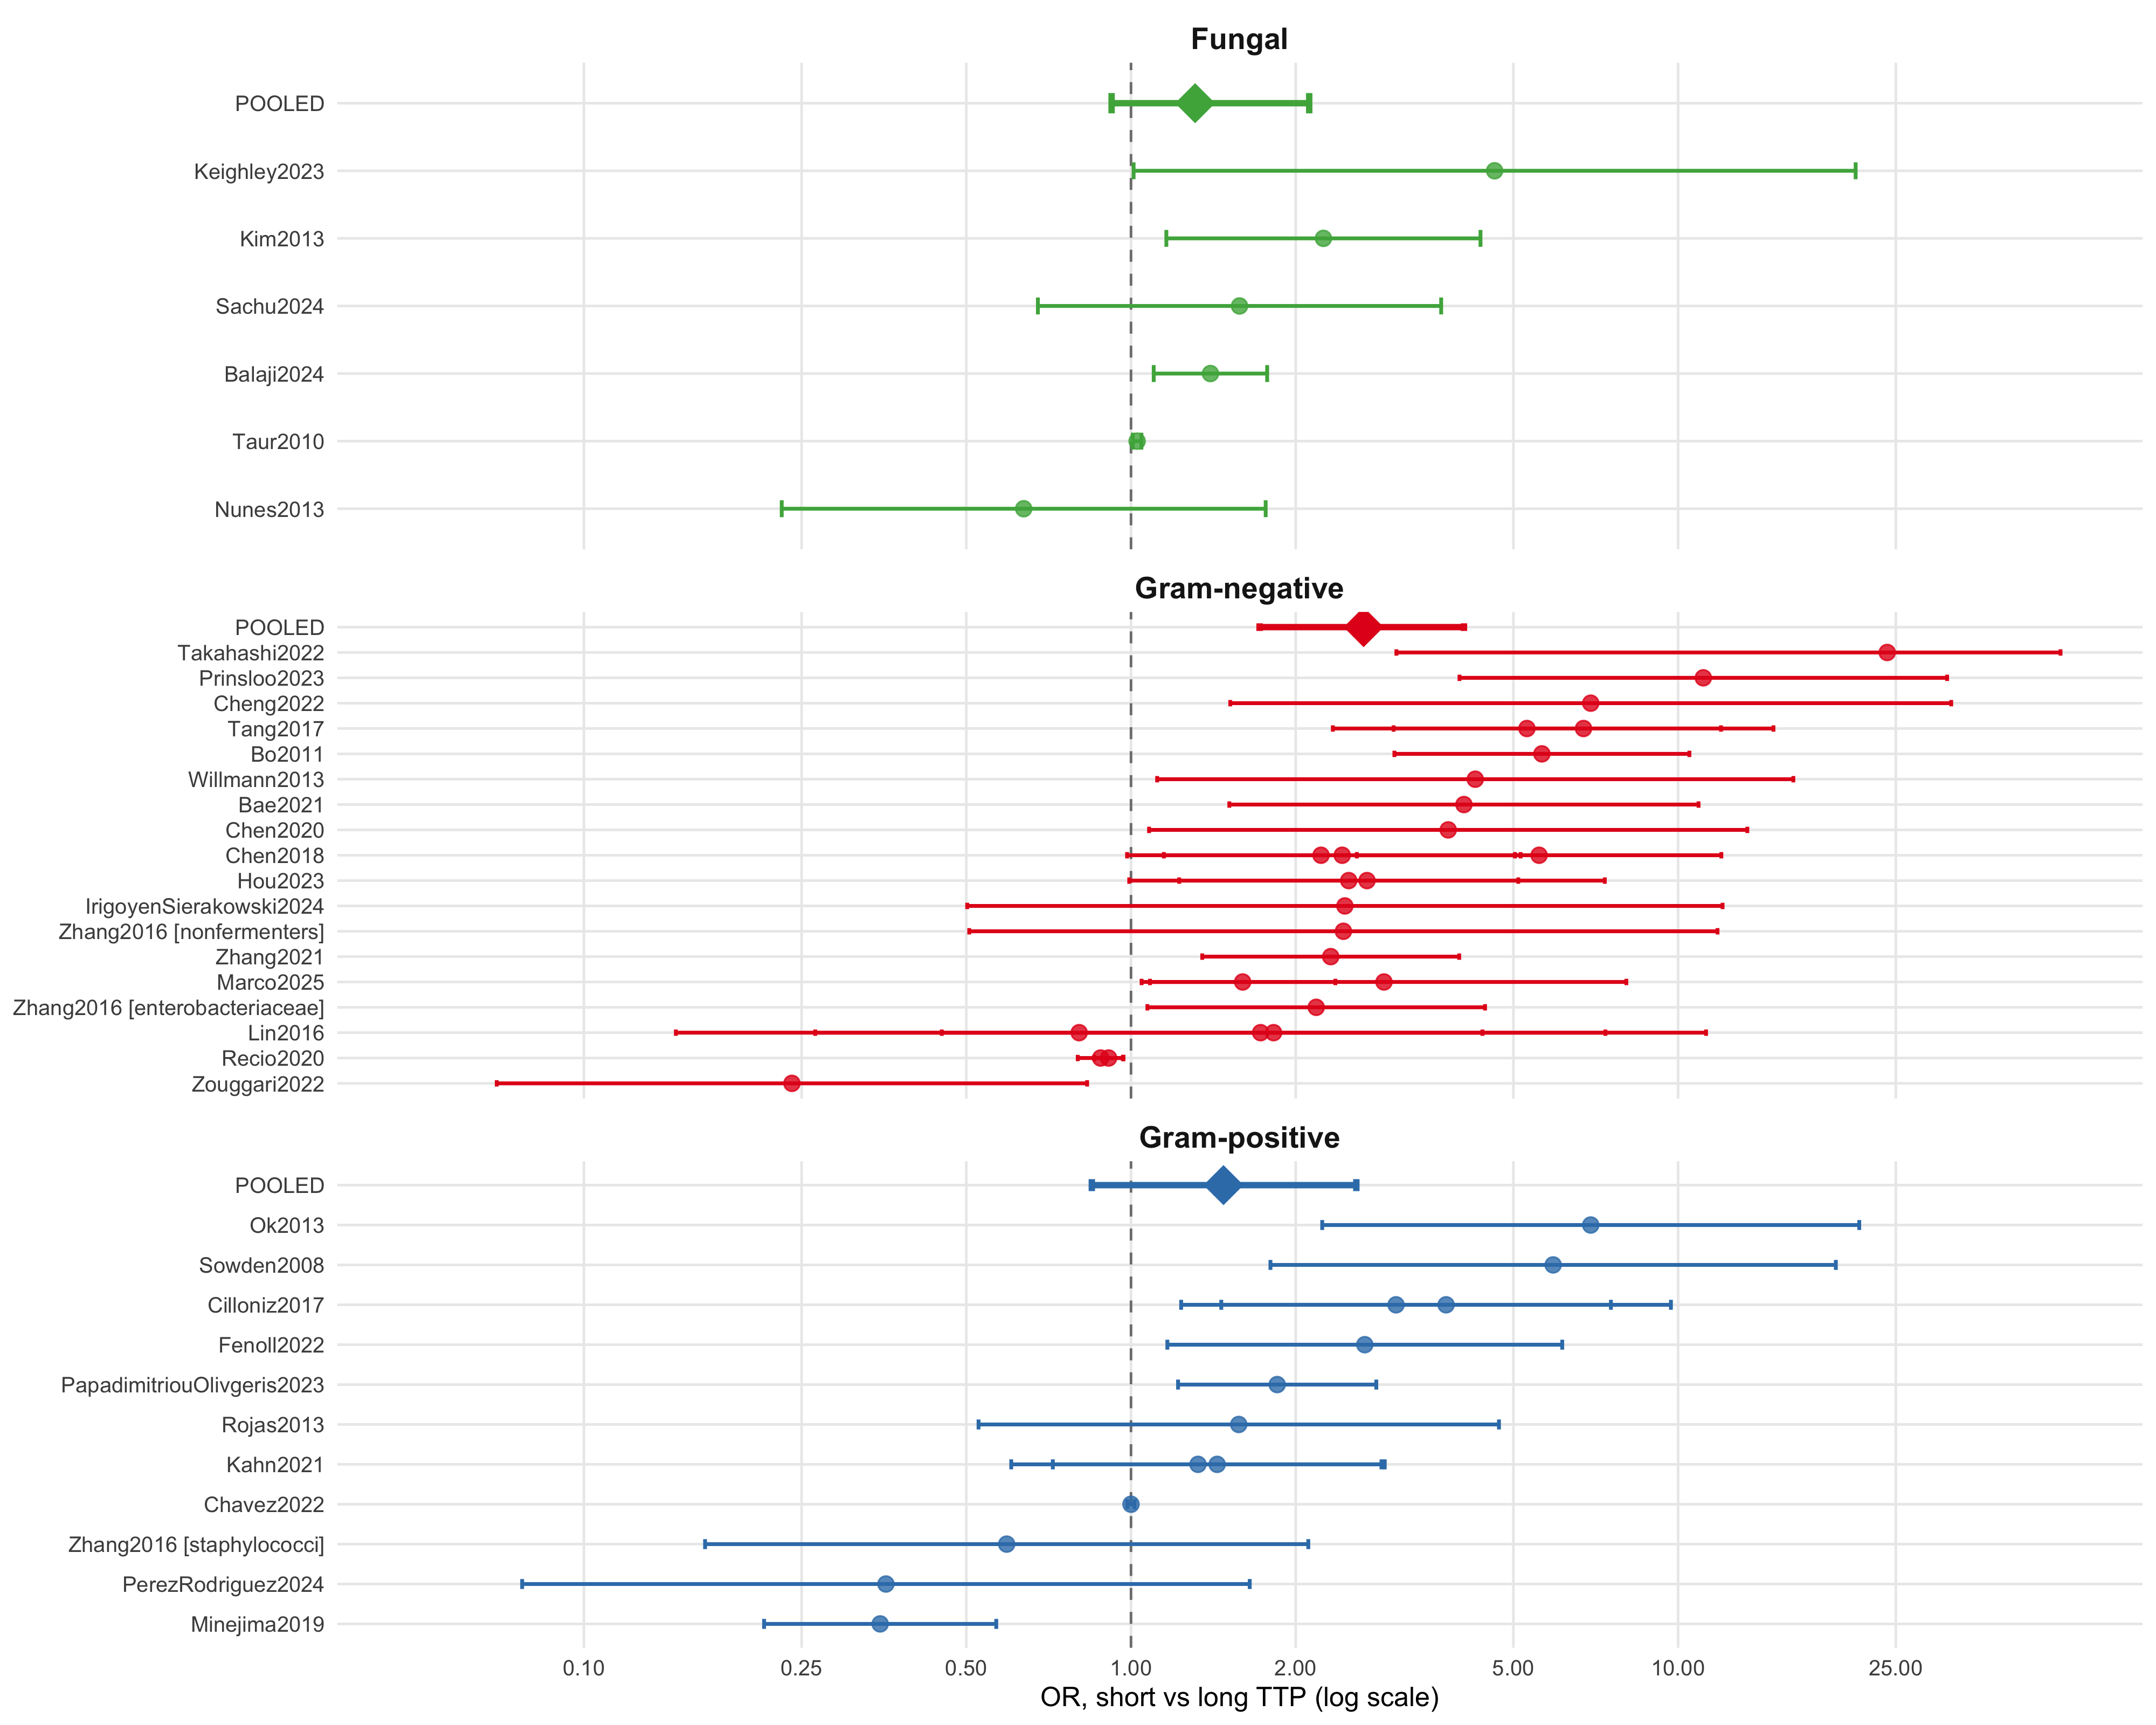

In [ ]:

pathogen_classes <- c("gram_negative", "gram_positive", "fungal")
pathogen_labels  <- c(
  gram_negative = "Gram-negative",
  gram_positive = "Gram-positive",
  fungal        = "Fungal"
)
pathogen_colours <- c(
  gram_negative = "#E41A1C",
  gram_positive = "#377EB8",
  fungal        = "#4DAF4A"
)

study_df <- es_mort |>
  filter(pathogen_class %in% pathogen_classes) |>
  mutate(
    or      = exp(yi),
    ci_low  = exp(yi - 1.96 * sei),
    ci_high = exp(yi + 1.96 * sei),
    lbl     = paste0(study_id,
                     ifelse(arm_id == "all", "", paste0(" [", arm_id, "]")))
  )

pooled_pts <- bind_rows(
  if (!is.null(post_gneg)) tibble(lbl = "POOLED", pathogen_class = "gram_negative",
    or = post_gneg$median_OR, ci_low = post_gneg$ci_OR[1], ci_high = post_gneg$ci_OR[2]),
  if (!is.null(post_gpos)) tibble(lbl = "POOLED", pathogen_class = "gram_positive",
    or = post_gpos$median_OR, ci_low = post_gpos$ci_OR[1], ci_high = post_gpos$ci_OR[2]),
  if (!is.null(post_fung)) tibble(lbl = "POOLED", pathogen_class = "fungal",
    or = post_fung$median_OR, ci_low = post_fung$ci_OR[1], ci_high = post_fung$ci_OR[2])
)

ggplot(study_df,
       aes(x = or, y = reorder(lbl, or), color = pathogen_class)) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "gray50") +
  geom_point(size = 2.2, alpha = 0.8) +
  geom_errorbar(aes(xmin = pmax(ci_low, 0.05), xmax = pmin(ci_high, 50)),
                width = 0.25, linewidth = 0.6) +
  # Pooled diamonds
  geom_point(data = pooled_pts,
             aes(x = or, y = lbl, color = pathogen_class),
             shape = 18, size = 6, inherit.aes = FALSE) +
  geom_errorbar(data = pooled_pts,
                aes(x = or, y = lbl, xmin = pmax(ci_low, 0.05),
                    xmax = pmin(ci_high, 50), color = pathogen_class),
                width = 0.3, linewidth = 1.0, inherit.aes = FALSE) +
  scale_color_manual(values = pathogen_colours, labels = pathogen_labels) +
  scale_x_log10(breaks = c(0.1, 0.25, 0.5, 1, 2, 5, 10, 25),
                limits  = c(0.05, 50)) +
  facet_wrap(~ pathogen_class, scales = "free_y", ncol = 1,
             labeller = as_labeller(pathogen_labels)) +
  labs(x = "OR, short vs long TTP (log scale)", y = NULL, color = NULL) +
  theme_minimal(base_size = 9) +
  theme(legend.position = "none",
        strip.text = element_text(face = "bold", size = 10),
        panel.grid.major.y = element_line(color = "gray92"),
        panel.grid.minor   = element_blank())


> **Fungal pool caveat**
>
> Only 6 effect sizes contribute to the fungal estimate. The posterior is very wide and the result should be treated as hypothesis-generating only. A dedicated systematic review of TTP and mortality in candidaemia would be more informative.

------------------------------------------------------------------------

# Infection source

## Available data

In [ ]:
es_mort |>
  mutate(infection_source = coalesce(infection_source, "not reported")) |>
  count(infection_source, name = "Effect sizes") |>
  arrange(desc(`Effect sizes`)) |>
  mutate(
    `Poolable (≥5)?` = if_else(`Effect sizes` >= 5, "Yes", "No — too sparse"),
    infection_source = recode(infection_source,
      mixed        = "Mixed (various sources)",
      pulmonary    = "Pulmonary",
      endovascular = "Endovascular",
      line_related = "Line-related",
      unknown      = "Unknown",
      `not reported` = "Not reported"
    )
  ) |>
  rename(`Infection source` = infection_source) |>
  gt() |>
  tab_style(style = cell_fill(color = "#FEF3CD"),
            locations = cells_body(rows = `Poolable (≥5)?` == "No — too sparse")) |>
  tab_source_note("Categories with <5 effect sizes are highlighted. Separate pooled models are only fitted for categories with ≥5 observations.")


> **Limited granularity in this dataset**
>
> The `infection_source` field reflects the dominant or reported source per arm. Most studies enrolled mixed BSI populations without restricting to a single anatomical source, meaning `mixed` (n=42) is the only category with sufficient data for a standalone pooled estimate. The remaining categories (pulmonary, endovascular, line-related) each contribute ≤3 effect sizes and cannot be reliably pooled.

## Mixed-source pool vs overall

In [ ]:

es_mixed <- es_mort |> filter(infection_source == "mixed")

fit_mixed <- brm(
  bf(yi | se(sei) ~ 1 + (1 | study_id)),
  data    = es_mixed,
  prior   = c(prior(normal(0, 1),   class = "Intercept"),
              prior(cauchy(0, 0.5), class = "sd")),
  chains = 4, iter = 4000, warmup = 1000, cores = 4,
  control = list(adapt_delta = 0.99),
  file    = "_brms_cache/primary/fit_mixed_source",
  file_refit = "on_change",
  silent = 2, refresh = 0
)
post_mixed <- pooled_summary(fit_mixed)

bind_rows(
  tibble(Subgroup   = sprintf("Overall (n=%d)", nrow(es_mort)),
         N          = nrow(es_mort),
         `Median OR` = sprintf("%.2f", base_post$median_OR),
         `95% CrI`  = sprintf("[%.2f, %.2f]", base_post$ci_OR[1], base_post$ci_OR[2]),
         `P(harm)`  = sprintf("%.0f%%", base_post$p_harm * 100),
         `I²`       = sprintf("%.0f%%", base_post$median_i2)),
  tibble(Subgroup   = sprintf("Mixed source only (n=%d)", nrow(es_mixed)),
         N          = nrow(es_mixed),
         `Median OR` = sprintf("%.2f", post_mixed$median_OR),
         `95% CrI`  = sprintf("[%.2f, %.2f]", post_mixed$ci_OR[1], post_mixed$ci_OR[2]),
         `P(harm)`  = sprintf("%.0f%%", post_mixed$p_harm * 100),
         `I²`       = sprintf("%.0f%%", post_mixed$median_i2))
) |> gt()


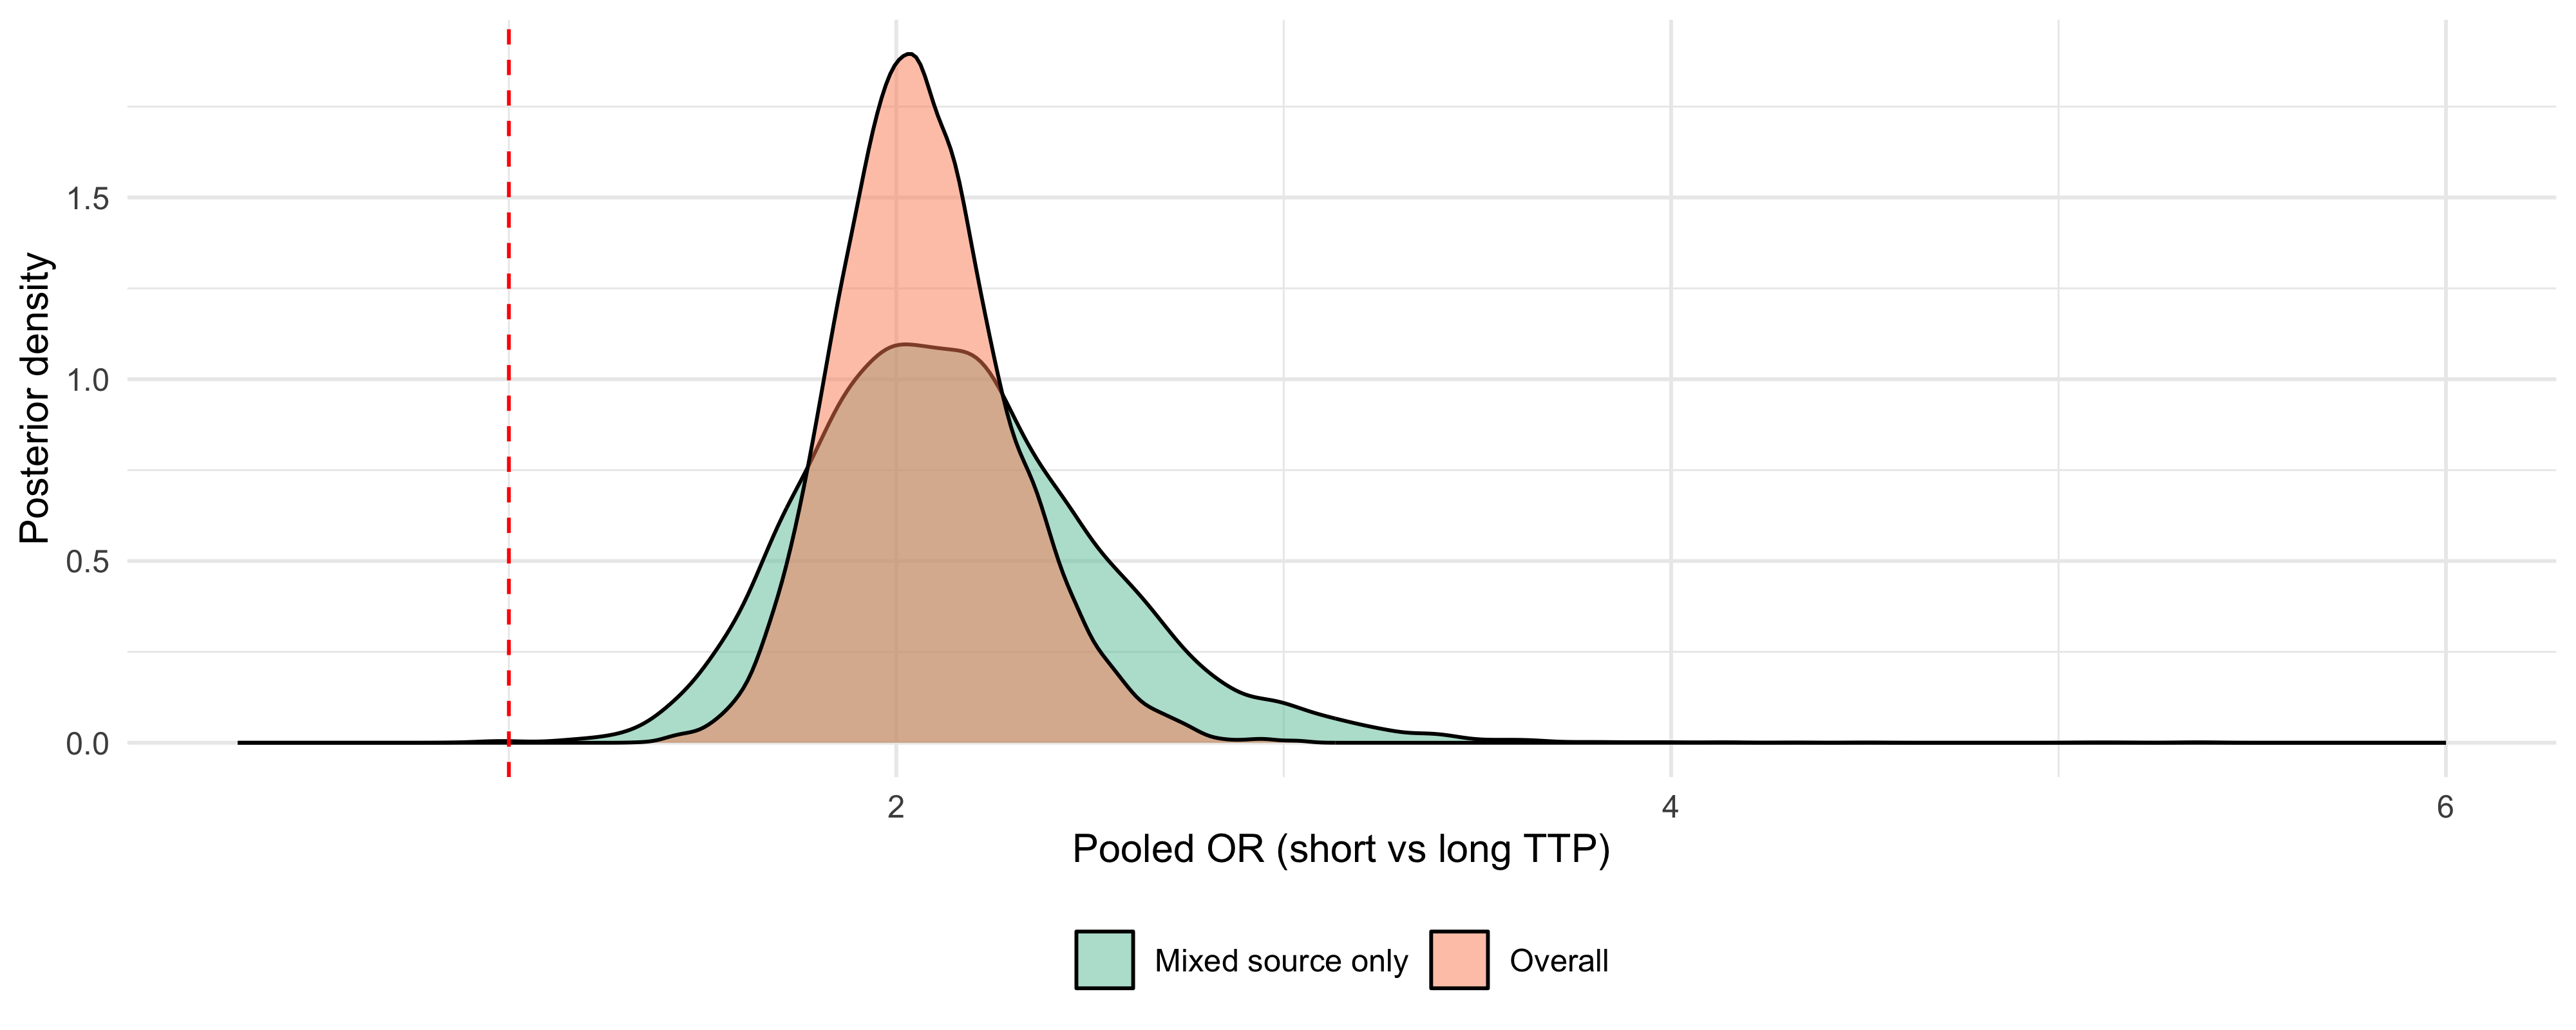

In [ ]:
bind_rows(
  tibble(OR = base_post$OR_draws,   Source = "Overall"),
  tibble(OR = post_mixed$OR_draws,  Source = "Mixed source only")
) |>
  ggplot(aes(x = OR, fill = Source)) +
  geom_density(alpha = 0.50) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "red") +
  scale_x_continuous(limits = c(0.3, 6)) +
  scale_fill_brewer(palette = "Set2") +
  labs(x = "Pooled OR (short vs long TTP)", y = "Posterior density", fill = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom")


## Binary meta-regression: mixed vs non-mixed source

In [ ]:

es_src_bin <- es_mort |>
  filter(!is.na(infection_source), infection_source != "unknown") |>
  mutate(is_mixed = factor(if_else(infection_source == "mixed",
                                   "mixed", "non-mixed"),
                           levels = c("non-mixed", "mixed")))

if (n_distinct(es_src_bin$is_mixed) == 2 && nrow(es_src_bin) >= 8) {
  fit_src_bin <- brm(
    bf(yi | se(sei) ~ 1 + is_mixed + (1 | study_id)),
    data    = es_src_bin,
    prior   = c(prior(normal(0, 1),   class = "Intercept"),
                prior(cauchy(0, 0.5), class = "sd"),
                prior(normal(0, 0.5), class = "b")),
    chains = 4, iter = 4000, warmup = 1000, cores = 4,
    control = list(adapt_delta = 0.99),
    file    = "_brms_cache/primary/fit_src_binary",
    file_refit = "on_change",
    silent = 2, refresh = 0
  )

  d <- as_draws_df(fit_src_bin)
  b <- d$b_is_mixedmixed

  tibble(
    Contrast    = "Mixed vs non-mixed infection source",
    `Δ log-OR`  = sprintf("%+.3f", median(b)),
    `95% CrI`   = sprintf("[%+.3f, %+.3f]", quantile(b, 0.025), quantile(b, 0.975)),
    `P(Δ > 0)`  = sprintf("%.0f%%", mean(b > 0) * 100)
  ) |> gt()
} else {
  cat("Insufficient data for binary meta-regression after excluding unknowns.")
}
